In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,47.916667,0.0,33.333333,0.000000,2.083333,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,46.212121,22.727273,26.515152,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,8.333333,0.0,65.972222,2.777778,11.805556,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,76.515152,0.000000,4.545455,Arkansas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-97.25,0.230,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,77.272727,22.727273,North Dakota
33395117,48.95,-97.15,0.115,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,36.111111,59.027778,Minnesota
33395118,48.95,-97.05,0.075,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,12.878788,0.757576,Minnesota
33395119,48.95,-96.95,0.025,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,25.000000,0.0,0.000000,0.000000,0.000000,Minnesota


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name'],
      dtype='object')

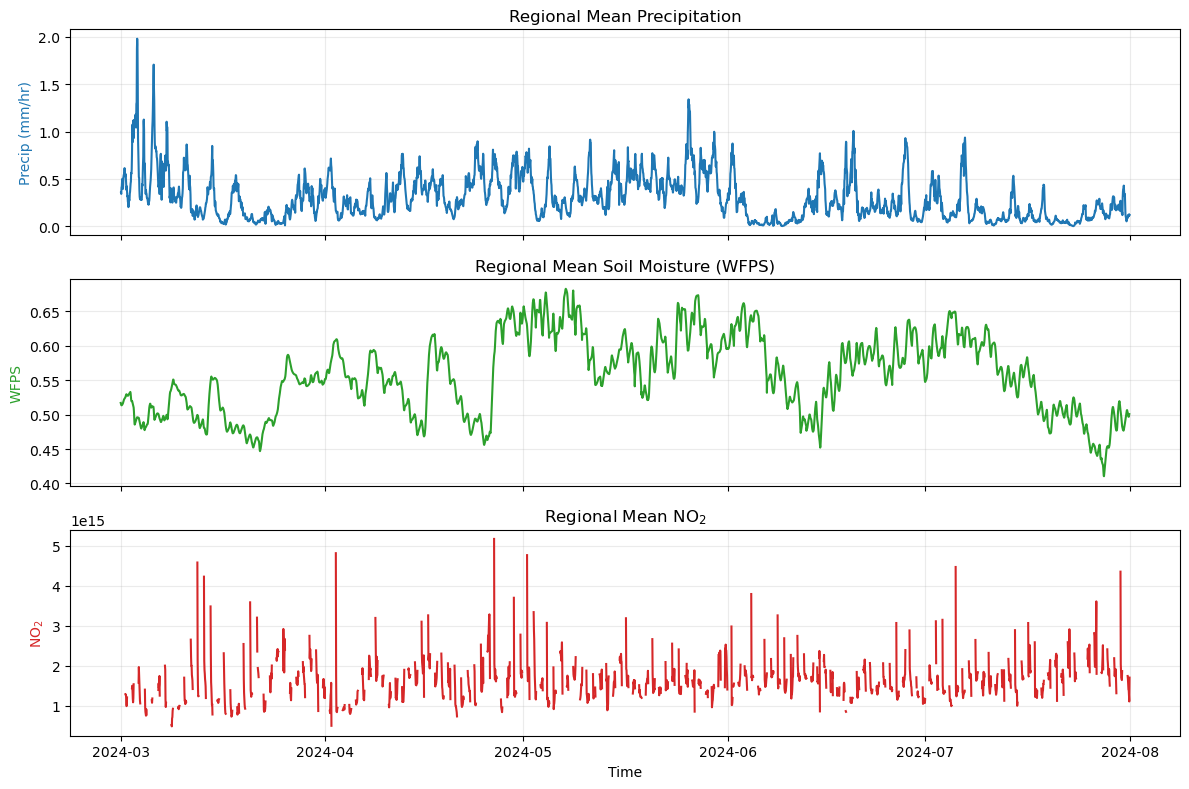

In [5]:
df_plot =df.copy()
df_plot["datetime"] =pd.to_datetime(df_plot["datetime"])

#agg over region
regional = (df_plot.groupby("datetime").agg(WFPS=("WFPS_c", "mean"),
                                            NO2=("no2_mean", "mean"),
                                            precip=("h_precip_mm", "mean"))
            .reset_index())

#subplots
fig, axes = plt.subplots(3, 1,figsize=(12, 8),sharex=True)

#precip
axes[0].plot(regional["datetime"],regional["precip"],color="tab:blue")
axes[0].set_ylabel("Precip (mm/hr)", color="tab:blue")
axes[0].set_title("Regional Mean Precipitation")
axes[0].grid(alpha=0.25)

#soil moisture
axes[1].plot(regional["datetime"],regional["WFPS"],color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green")
axes[1].set_title("Regional Mean Soil Moisture (WFPS)")
axes[1].grid(alpha=0.25)

#no2
axes[2].plot(regional["datetime"],regional["NO2"],color="tab:red")
axes[2].set_ylabel("NO$_2$", color="tab:red")
axes[2].set_title("Regional Mean NO$_2$")
axes[2].grid(alpha=0.25)

# shared x-axis
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

Grid cell with most pulses: lat=36.65, lon=-89.35, pulses=4


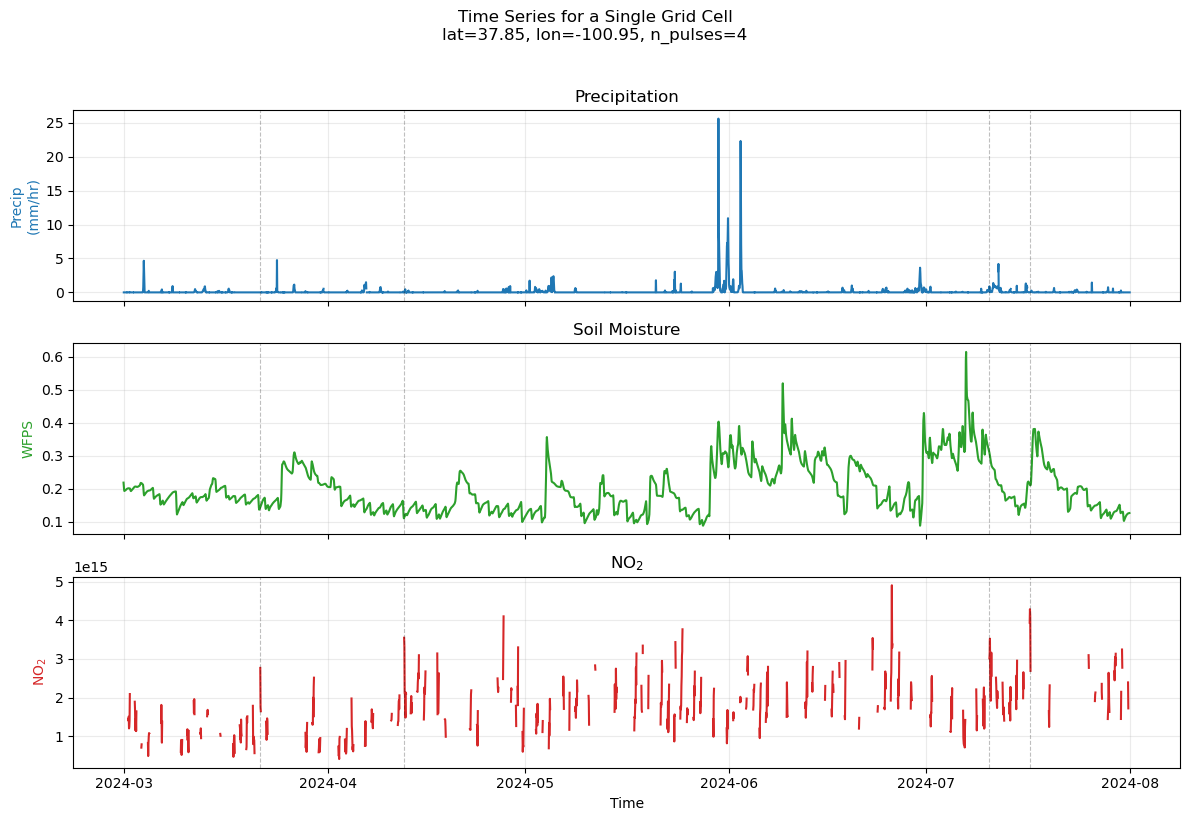

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# find grid cell with most pulses
pulse_counts = (
    df_plot[df_plot["pulse_start"] == True]
    .groupby(["grid_lat", "grid_lon"])
    .size()
    .sort_values(ascending=False)
)

top_lat, top_lon = pulse_counts.index[0]
top_n_pulses = pulse_counts.iloc[0]

print(f"Grid cell with most pulses: lat={top_lat}, lon={top_lon}, pulses={top_n_pulses}")

valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values("n_pulses", ascending=False)

top_lat = valid_cells.iloc[0]["grid_lat"]
top_lon = valid_cells.iloc[0]["grid_lon"]
top_n_pulses = valid_cells.iloc[0]["n_pulses"]

cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()


# optional: mark pulse times
pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

# plot
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 8),
    sharex=True
)

# precipitation
axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue")
axes[0].set_title("Precipitation")
axes[0].grid(alpha=0.25)

# soil moisture
axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green")
axes[1].set_title("Soil Moisture")
axes[1].grid(alpha=0.25)

# NO2
axes[2].plot(cell_df["datetime"], cell_df["no2_mean"], color="tab:red")
axes[2].set_ylabel("NO$_2$", color="tab:red")
axes[2].set_title("NO$_2$")
axes[2].set_xlabel("Time")
axes[2].grid(alpha=0.25)

# add vertical pulse markers to all panels
for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.25, linewidth=0.8)

fig.suptitle(
    f"Time Series for a Single Grid Cell\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, n_pulses={top_n_pulses}",
    y=1.02
)

plt.tight_layout()
plt.show()

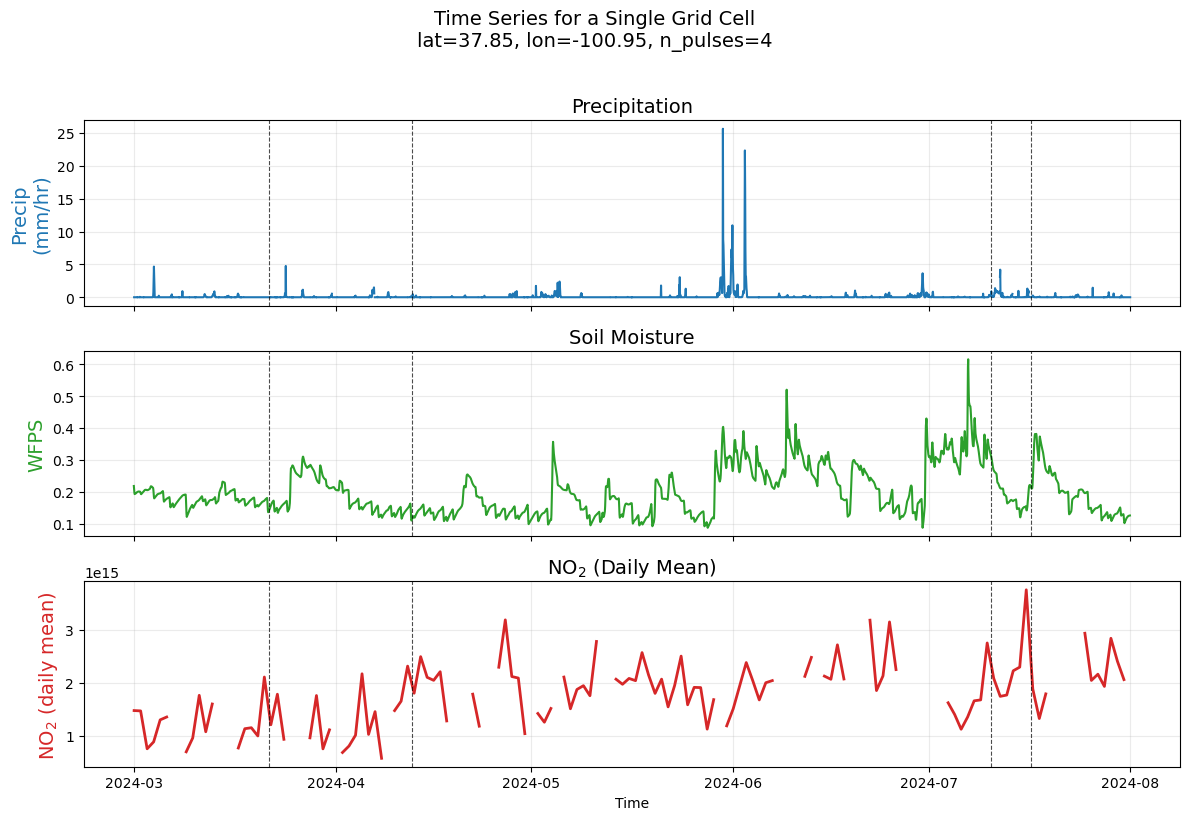

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# -----------------------------
# find best grid cell
# -----------------------------
valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values("n_pulses", ascending=False)

top_lat = valid_cells.iloc[0]["grid_lat"]
top_lon = valid_cells.iloc[0]["grid_lon"]
top_n_pulses = valid_cells.iloc[0]["n_pulses"]

# -----------------------------
# subset cell
# -----------------------------
cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()

# -----------------------------
# DAILY NO2 ONLY
# -----------------------------
no2_daily = (
    cell_df.set_index("datetime")["no2_mean"]
    .resample("1D")
    .mean()
)

# -----------------------------
# pulse times (keep original resolution)
# -----------------------------
pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

# -----------------------------
# plot
# -----------------------------
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# precip (hourly)
axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue",fontsize=14)
axes[0].set_title("Precipitation",fontsize=14)
axes[0].grid(alpha=0.25)

# soil moisture (hourly)
axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green",fontsize=14)
axes[1].set_title("Soil Moisture",fontsize=14)
axes[1].grid(alpha=0.25)

# NO2 (daily average)
axes[2].plot(
    no2_daily.index,
    no2_daily.values,
    color="tab:red",
    linewidth=2
)
axes[2].set_ylabel("NO$_2$ (daily mean)", color="tab:red", fontsize=14)
axes[2].set_title("NO$_2$ (Daily Mean)",fontsize=14)
axes[2].set_xlabel("Time")
axes[2].grid(alpha=0.25)

# -----------------------------
# pulse markers (same as before)
# -----------------------------
for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.7, linewidth=0.8)

# -----------------------------
# title
# -----------------------------
fig.suptitle(
    f"Time Series for a Single Grid Cell\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, n_pulses={top_n_pulses}",
    y=1.02, fontsize=14
)

plt.tight_layout()
plt.show()

Grid cell rank 16: lat=38.05, lon=-90.25, pulses=3, total_precip=906.08


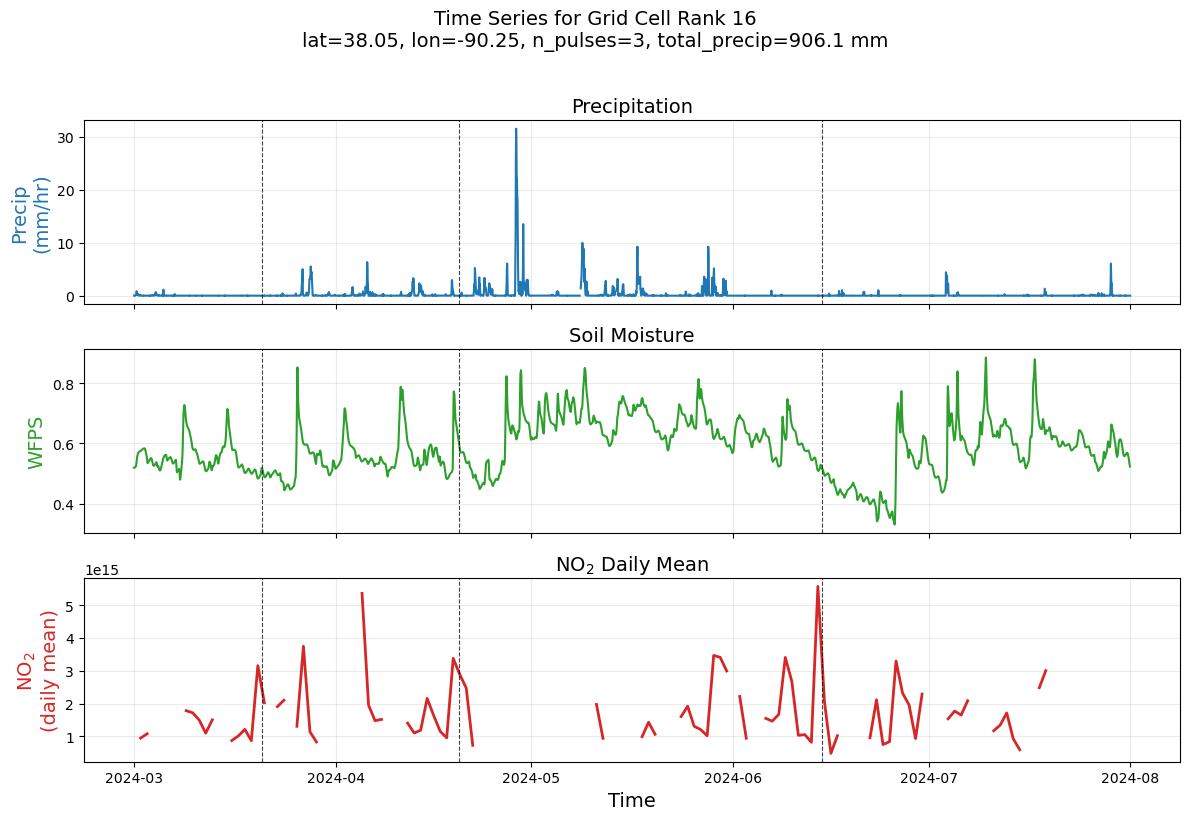

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# choose which grid cell to plot
rank = 16 # 0 = most pulses, 1 = second-most, 2 = third-most, etc.

valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values(["n_pulses", "total_precip"], ascending=False)

top_lat = valid_cells.iloc[rank]["grid_lat"]
top_lon = valid_cells.iloc[rank]["grid_lon"]
top_n_pulses = valid_cells.iloc[rank]["n_pulses"]
top_total_precip = valid_cells.iloc[rank]["total_precip"]

print(
    f"Grid cell rank {rank}: "
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"pulses={top_n_pulses}, total_precip={top_total_precip:.2f}"
)

cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()

no2_daily = (
    cell_df.set_index("datetime")["no2_mean"]
    .resample("1D")
    .mean()
)

pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue",fontsize=14)
axes[0].set_title("Precipitation",fontsize=14)
axes[0].grid(alpha=0.25)

axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green",fontsize=14)
axes[1].set_title("Soil Moisture",fontsize=14)
axes[1].grid(alpha=0.25)

axes[2].plot(no2_daily.index, no2_daily.values, color="tab:red", linewidth=2)
axes[2].set_ylabel("NO$_2$\n(daily mean)", color="tab:red",fontsize=14)
axes[2].set_title("NO$_2$ Daily Mean",fontsize=14)
axes[2].set_xlabel("Time",fontsize=14)
axes[2].grid(alpha=0.25)

for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.75, linewidth=0.8)

fig.suptitle(
    f"Time Series for Grid Cell Rank {rank}\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"n_pulses={top_n_pulses}, total_precip={top_total_precip:.1f} mm",
    y=1.02, fontsize=14
)

plt.tight_layout()
plt.show()

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed
/tmp/ipykernel_1223157/494350921.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  soil_map["soil_code"] = soil_types.cat.codes


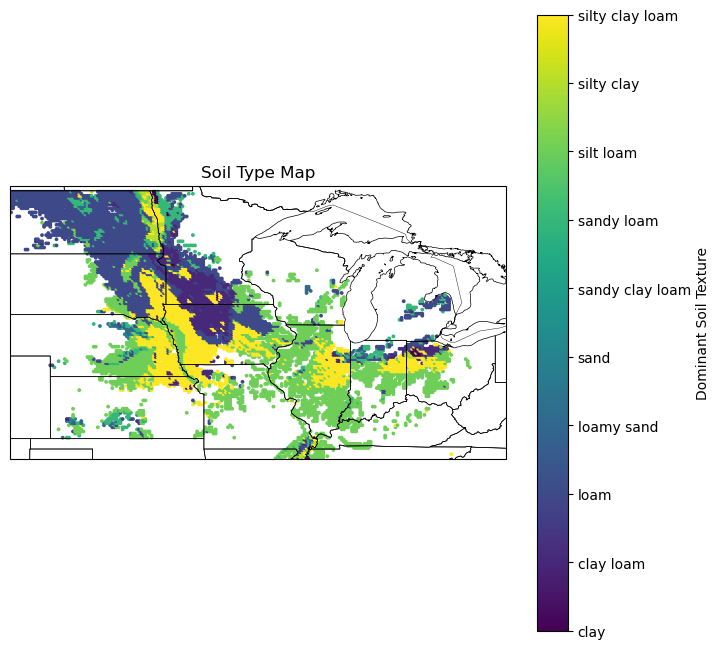

In [9]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# take one snapshot (soil doesn't change over time)
soil_map = df.drop_duplicates(subset=["grid_lat", "grid_lon"])

# map soil types to numbers for coloring
soil_types = soil_map["dominant_texture"].astype("category")
soil_map["soil_code"] = soil_types.cat.codes

plt.figure(figsize=(8,8))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([-104, -80, 36, 49])  # Midwest bounds (adjust if needed)

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.3)

sc = ax.scatter(
    soil_map["grid_lon"],
    soil_map["grid_lat"],
    c=soil_map["soil_code"],
    s=3,
    transform=ccrs.PlateCarree()
)

# colorbar with labels
cbar = plt.colorbar(sc, ax=ax)
cbar.set_ticks(range(len(soil_types.cat.categories)))
cbar.set_ticklabels(soil_types.cat.categories)
cbar.set_label("Dominant Soil Texture")

plt.title("Soil Type Map")
plt.show()

In [10]:
print(cell_df["h_precip_mm"].describe())
print("NaNs:", cell_df["h_precip_mm"].isna().sum())
print("Nonzero precip:", (cell_df["h_precip_mm"].fillna(0) > 0).sum())
print(cell_df[["datetime", "h_precip_mm"]].dropna().head())

count    3554.000000
mean        0.254947
std         1.372289
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        31.480000
Name: h_precip_mm, dtype: float64
NaNs: 125
Nonzero precip: 808
                 datetime  h_precip_mm
18684 2024-03-01 00:00:00          0.0
27764 2024-03-01 01:00:00          0.0
36844 2024-03-01 02:00:00          0.0
45924 2024-03-01 03:00:00          0.0
55004 2024-03-01 04:00:00          0.0


/tmp/ipykernel_1223157/3458391991.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", len(soil_types))  # categorical colormap


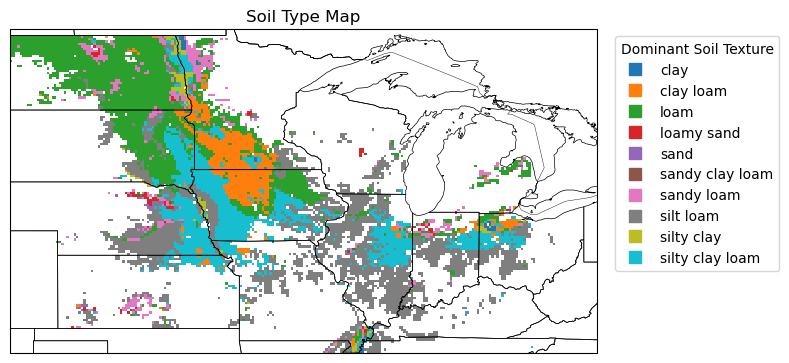

In [11]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors
import numpy as np

# ---- one row per grid cell ----
soil_map = df.drop_duplicates(subset=["grid_lat", "grid_lon"]).copy()

# ---- get unique soil types ----
soil_types = sorted(soil_map["dominant_texture"].dropna().unique())

# ---- assign colors ----
cmap = plt.cm.get_cmap("tab10", len(soil_types))  # categorical colormap
color_dict = {soil: cmap(i) for i, soil in enumerate(soil_types)}

# ---- estimate grid spacing (important!) ----
lat_vals = np.sort(soil_map["grid_lat"].unique())
lon_vals = np.sort(soil_map["grid_lon"].unique())

dlat = np.median(np.diff(lat_vals))
dlon = np.median(np.diff(lon_vals))

# ---- plot ----
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([-104, -80, 36, 49])

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.3)

# ---- draw rectangles ----
for _, row in soil_map.iterrows():
    soil = row["dominant_texture"]
    if pd.isna(soil):
        continue

    rect = Rectangle(
        (row["grid_lon"] - dlon/2, row["grid_lat"] - dlat/2),
        dlon,
        dlat,
        facecolor=color_dict[soil],
        edgecolor=None,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

# ---- legend ----
handles = [
    plt.Line2D([0], [0], marker='s', color=color_dict[soil],
               markersize=8, linestyle='None', label=soil)
    for soil in soil_types
]

ax.legend(
    handles=handles,
    title="Dominant Soil Texture",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.title("Soil Type Map")
plt.tight_layout()
plt.show()

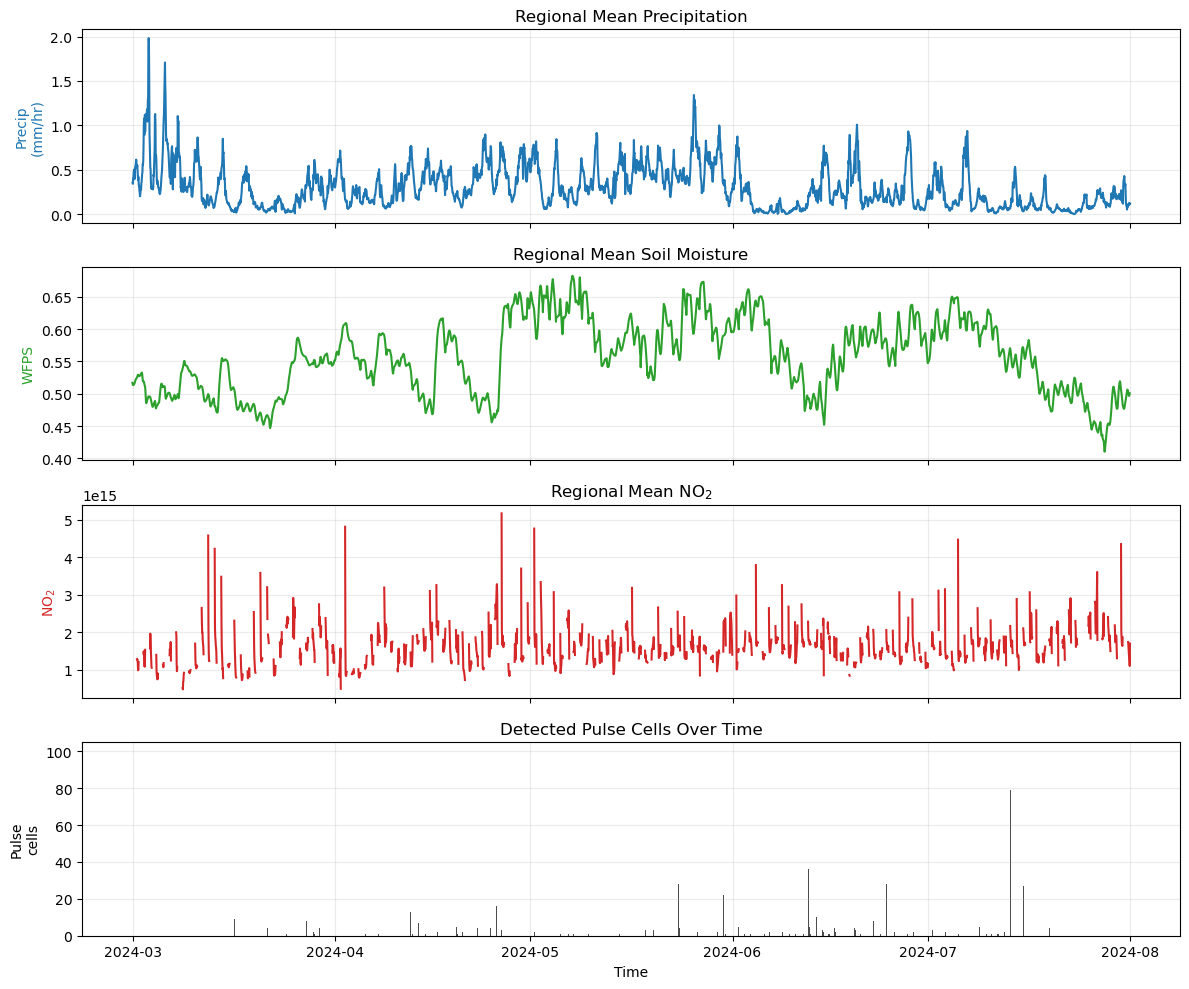

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# regional averages
regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean"),
        pulses=("pulse_start", "sum")   # counts pulse_start=True cells per timestamp
    )
    .reset_index()
)

fig, axes = plt.subplots(
    4, 1,
    figsize=(12, 10),
    sharex=True
)

# precip
axes[0].plot(regional["datetime"], regional["precip"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue")
axes[0].set_title("Regional Mean Precipitation")
axes[0].grid(alpha=0.25)

# WFPS
axes[1].plot(regional["datetime"], regional["WFPS"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green")
axes[1].set_title("Regional Mean Soil Moisture")
axes[1].grid(alpha=0.25)

# NO2
axes[2].plot(regional["datetime"], regional["NO2"], color="tab:red")
axes[2].set_ylabel("NO$_2$", color="tab:red")
axes[2].set_title("Regional Mean NO$_2$")
axes[2].grid(alpha=0.25)

# pulse detections
axes[3].bar(
    regional["datetime"],
    regional["pulses"],
    width=0.03,   # about ~45 min in datetime units
    color="black",
    alpha=0.7,
)
axes[3].set_ylabel("Pulse\ncells")
axes[3].set_title("Detected Pulse Cells Over Time")
axes[3].set_xlabel("Time")
axes[3].set_ylim(0, 105)  
axes[3].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Highlight windows:


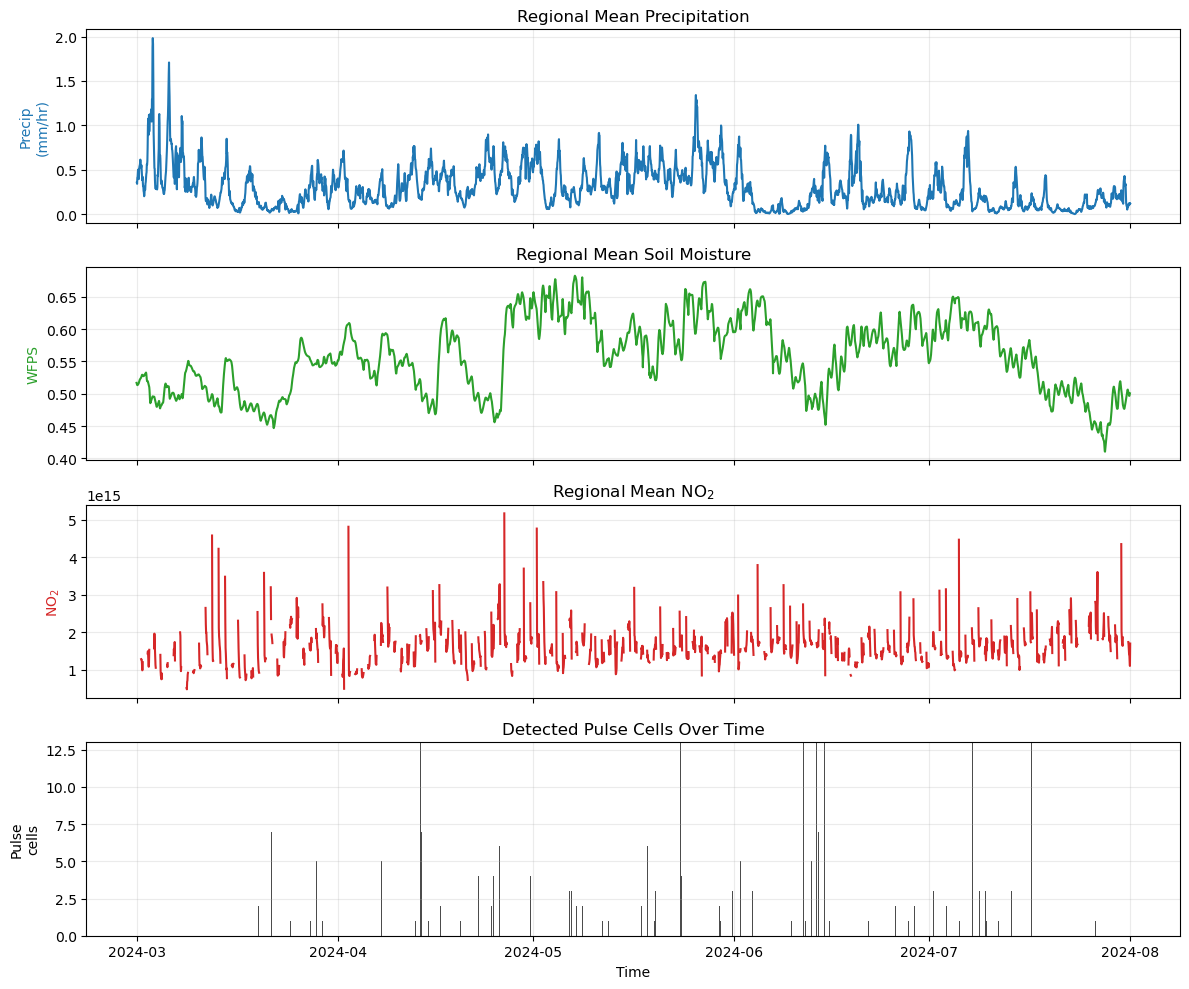

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean"),
        pulses=("pulse_start", "sum")
    )
    .reset_index()
    .sort_values("datetime")
)

# -----------------------------
# Detect candidate dry-down / NO2 increase periods
# -----------------------------
window = 24 * 3   # 3-day rolling window, change if needed

regional["precip_3d"] = regional["precip"].rolling(window, min_periods=12).sum()
regional["WFPS_change_3d"] = regional["WFPS"] - regional["WFPS"].shift(window)
regional["NO2_change_3d"] = regional["NO2"] - regional["NO2"].shift(window)

# conditions:
# low precip, WFPS decreasing, NO2 increasing
regional["highlight"] = (
    (regional["precip_3d"] < regional["precip_3d"].quantile(0.25)) &
    (regional["WFPS_change_3d"] < 0) &
    (regional["NO2_change_3d"] > 0)
)

# turn consecutive highlighted points into windows
highlight_windows = []
in_window = False

for i, row in regional.iterrows():
    if row["highlight"] and not in_window:
        start = row["datetime"]
        in_window = True

    if (not row["highlight"]) and in_window:
        end = regional.loc[i - 1, "datetime"]
        highlight_windows.append((start, end))
        in_window = False

if in_window:
    highlight_windows.append((start, regional["datetime"].iloc[-1]))

# optional: keep only windows lasting at least 12 hours
highlight_windows = [
    (s, e) for s, e in highlight_windows
    if (e - s) >= pd.Timedelta(hours=12)
]

print("Highlight windows:")
for s, e in highlight_windows:
    print(s, "to", e)

# -----------------------------
# Plot with highlights
# -----------------------------
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

axes[0].plot(regional["datetime"], regional["precip"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue")
axes[0].set_title("Regional Mean Precipitation")
axes[0].grid(alpha=0.25)

axes[1].plot(regional["datetime"], regional["WFPS"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green")
axes[1].set_title("Regional Mean Soil Moisture")
axes[1].grid(alpha=0.25)

axes[2].plot(regional["datetime"], regional["NO2"], color="tab:red")
axes[2].set_ylabel("NO$_2$", color="tab:red")
axes[2].set_title("Regional Mean NO$_2$")
axes[2].grid(alpha=0.25)

axes[3].bar(
    regional["datetime"],
    regional["pulses"],
    width=0.03,
    color="black",
    alpha=0.7
)
axes[3].set_ylabel("Pulse\ncells")
axes[3].set_title("Detected Pulse Cells Over Time")
axes[3].set_xlabel("Time")
axes[3].set_ylim(0, regional["pulses"].quantile(0.99))
axes[3].grid(alpha=0.25)

# add highlight bars to all panels
for ax in axes:
    for start, end in highlight_windows:
        ax.axvspan(start, end, color="orange", alpha=0.18, zorder=0)

plt.tight_layout()
plt.show()

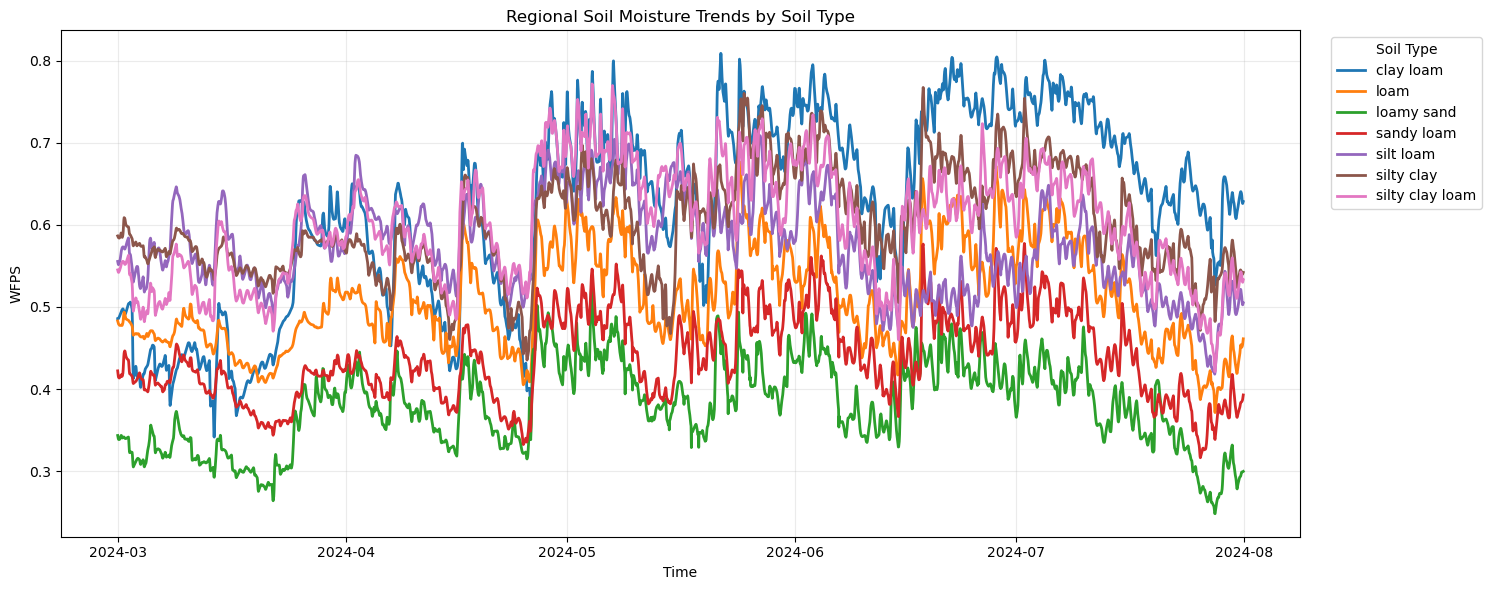

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# ---- optional: reduce clutter (HIGHLY recommended) ----
top_soils = (
    df_plot["dominant_texture"]
    .value_counts()
    .head(7)
    .index
)

df_plot = df_plot[df_plot["dominant_texture"].isin(top_soils)]

# ---- aggregate by time + soil type ----
soil_ts = (
    df_plot.groupby(["datetime", "dominant_texture"])
    .agg(WFPS=("WFPS_c", "mean"))
    .reset_index()
)

# ---- plot ----
plt.figure(figsize=(15,6))

sns.lineplot(
    data=soil_ts,
    x="datetime",
    y="WFPS",
    hue="dominant_texture",
    linewidth=2
)

plt.title("Regional Soil Moisture Trends by Soil Type")
plt.xlabel("Time")
plt.ylabel("WFPS")
plt.legend(
    title="Soil Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1223157/4043316896.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", len(soil_types))


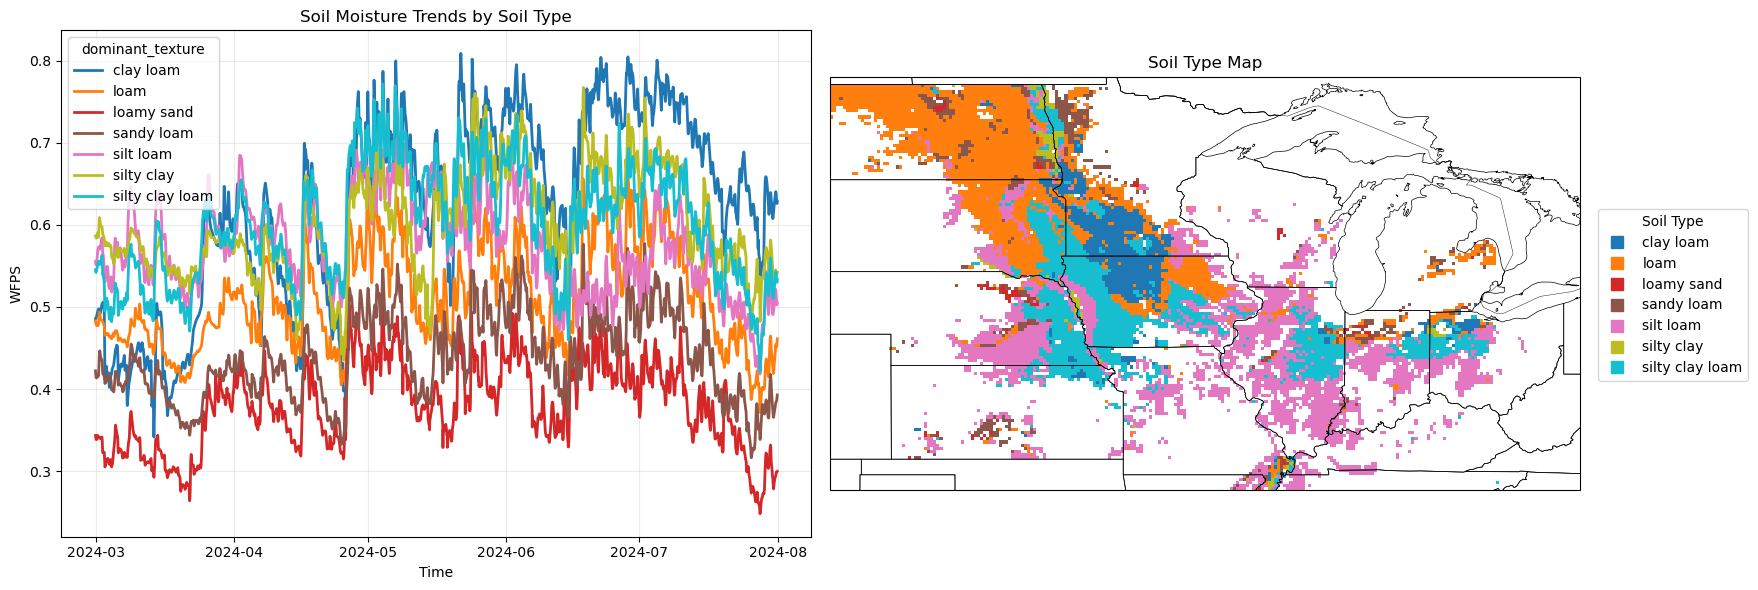

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
import numpy as np

# -----------------------------
# PREP DATA
# -----------------------------
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# pick top soils (same for both plots!)
top_soils = (
    df_plot["dominant_texture"]
    .value_counts()
    .head(7)
    .index
)

df_plot = df_plot[df_plot["dominant_texture"].isin(top_soils)]

# -----------------------------
# SHARED COLOR MAP
# -----------------------------
soil_types = sorted(top_soils)

cmap = plt.cm.get_cmap("tab10", len(soil_types))
color_dict = {soil: cmap(i) for i, soil in enumerate(soil_types)}

# -----------------------------
# TIME SERIES DATA
# -----------------------------
soil_ts = (
    df_plot.groupby(["datetime", "dominant_texture"])
    .agg(WFPS=("WFPS_c", "mean"))
    .reset_index()
)

# -----------------------------
# MAP DATA
# -----------------------------
soil_map = (
    df_plot.drop_duplicates(subset=["grid_lat", "grid_lon"])
    .copy()
)

lat_vals = np.sort(soil_map["grid_lat"].unique())
lon_vals = np.sort(soil_map["grid_lon"].unique())

dlat = np.median(np.diff(lat_vals))
dlon = np.median(np.diff(lon_vals))

# -----------------------------
# FIGURE (SIDE BY SIDE)
# -----------------------------
fig = plt.figure(figsize=(16, 6))

# ---- LEFT: TIME SERIES ----
ax1 = fig.add_subplot(1, 2, 1)

sns.lineplot(
    data=soil_ts,
    x="datetime",
    y="WFPS",
    hue="dominant_texture",
    palette=color_dict,   # <-- KEY LINE
    linewidth=2,
    ax=ax1
)

ax1.set_title("Soil Moisture Trends by Soil Type")
ax1.set_xlabel("Time")
ax1.set_ylabel("WFPS")
ax1.grid(alpha=0.25)

# ---- RIGHT: MAP ----
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())

ax2.set_extent([-104, -80, 36, 49])

ax2.add_feature(cfeature.STATES, linewidth=0.5)
ax2.add_feature(cfeature.BORDERS, linewidth=0.3)
ax2.add_feature(cfeature.COASTLINE, linewidth=0.3)

# draw rectangles
for _, row in soil_map.iterrows():
    soil = row["dominant_texture"]
    if pd.isna(soil) or soil not in color_dict:
        continue

    rect = Rectangle(
        (row["grid_lon"] - dlon/2, row["grid_lat"] - dlat/2),
        dlon,
        dlat,
        facecolor=color_dict[soil],   # <-- SAME COLORS
        edgecolor=None,
        transform=ccrs.PlateCarree()
    )
    ax2.add_patch(rect)

ax2.set_title("Soil Type Map")

# -----------------------------
# SHARED LEGEND (cleaner)
# -----------------------------
handles = [
    plt.Line2D([0], [0], marker='s', color=color_dict[soil],
               markersize=8, linestyle='None', label=soil)
    for soil in soil_types
]

fig.legend(
    handles=handles,
    title="Soil Type",
    loc="center right",
    bbox_to_anchor=(1.1, 0.5)
)

plt.tight_layout()
plt.show()

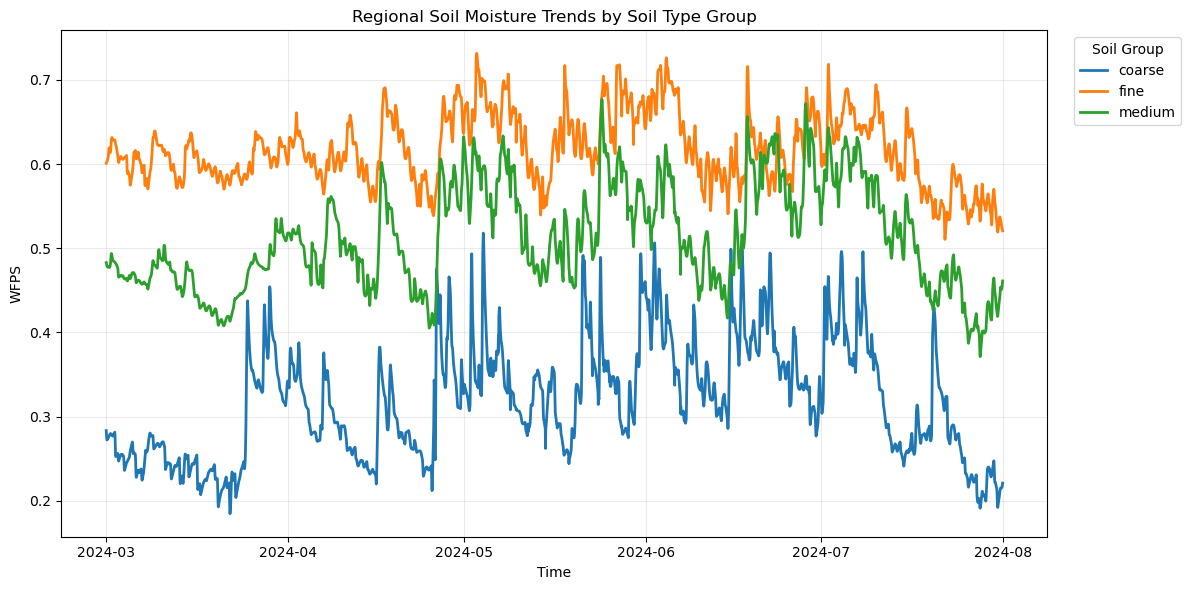

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

soil_group_map = {
    "sand": "coarse",
    "loamy_sand": "coarse",
    "sandy_loam": "moderately_coarse",
    "loam": "medium",
    "silt_loam": "medium",
    "clay_loam": "moderately_fine",
    "silty_clay_loam": "moderately_fine",
    "clay": "fine",
    "silty_clay": "fine",
    "sandy_clay": "fine",
    "sandy_clay_loam": "moderately_fine",
    "silt": "medium"
}

df_plot["soil_group"] = df_plot["dominant_texture"].map(soil_group_map)

df_plot = df_plot.dropna(subset=["soil_group", "WFPS_c"])

soil_ts = (
    df_plot.groupby(["datetime", "soil_group"], observed=True)
    .agg(WFPS=("WFPS_c", "mean"))
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=soil_ts,
    x="datetime",
    y="WFPS",
    hue="soil_group",
    linewidth=2
)

plt.title("Regional Soil Moisture Trends by Soil Type Group")
plt.xlabel("Time")
plt.ylabel("WFPS")
plt.legend(
    title="Soil Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

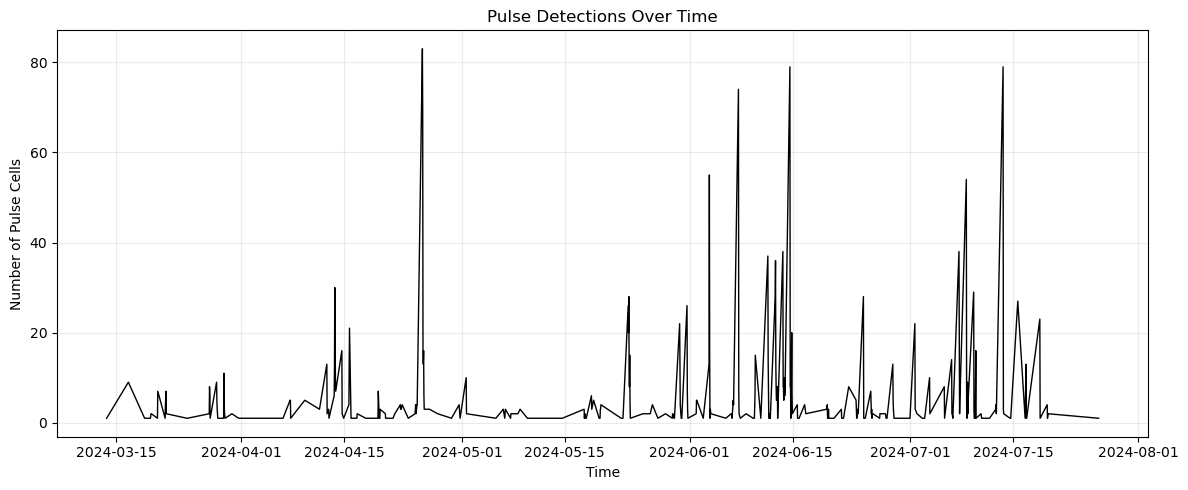

In [17]:
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# count pulses per timestamp
pulse_ts = (
    df_plot[df_plot["pulse_start"] == True]
    .groupby("datetime")
    .size()
    .reset_index(name="n_pulses")
)

# plot
plt.figure(figsize=(12,5))

plt.plot(
    pulse_ts["datetime"],
    pulse_ts["n_pulses"],
    color="black",
    linewidth=1
)

plt.xlabel("Time")
plt.ylabel("Number of Pulse Cells")
plt.title("Pulse Detections Over Time")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

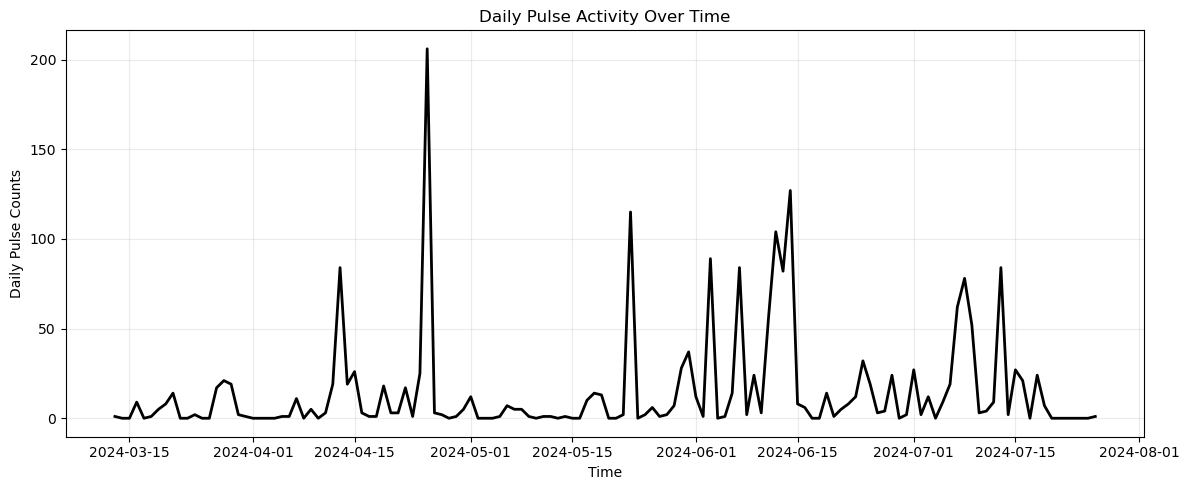

In [18]:
pulse_daily = (
    pulse_ts.set_index("datetime")
    .resample("1D")
    .sum()
    .reset_index()
)

plt.figure(figsize=(12,5))

plt.plot(
    pulse_daily["datetime"],
    pulse_daily["n_pulses"],
    color="black",
    linewidth=2
)

plt.xlabel("Time")
plt.ylabel("Daily Pulse Counts")
plt.title("Daily Pulse Activity Over Time")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

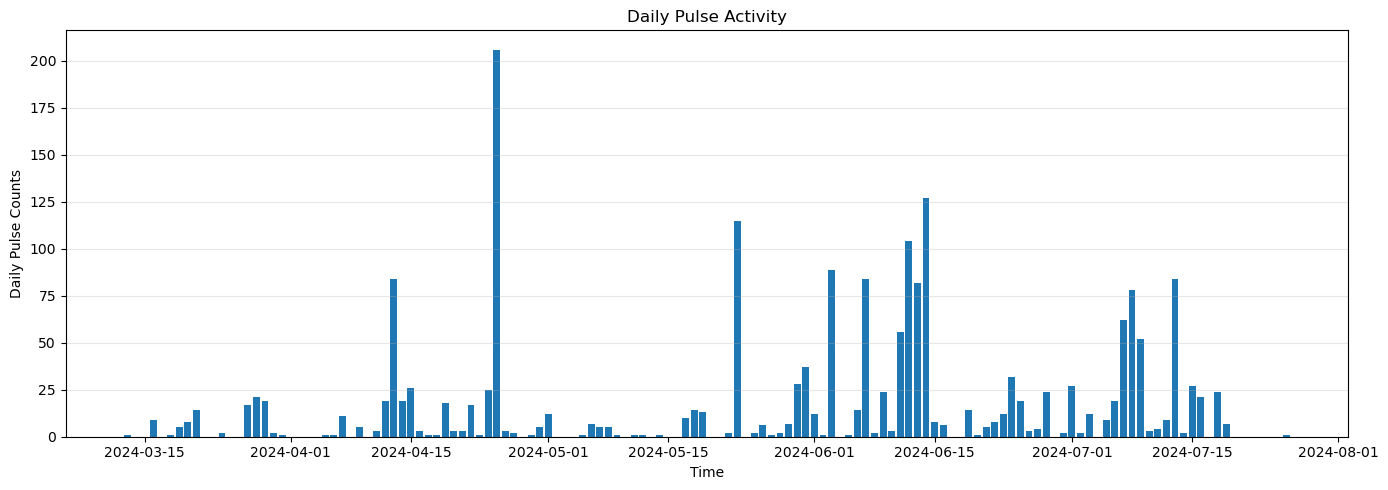

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# count pulses per timestamp
pulse_ts = (
    df_plot[df_plot["pulse_start"] == True]
    .groupby("datetime")
    .size()
    .reset_index(name="n_pulses")
)

# aggregate to daily
pulse_daily = (
    pulse_ts.set_index("datetime")
    .resample("1D")
    .sum()
    .reset_index()
)

# ---- BAR PLOT ----
plt.figure(figsize=(14,5))

plt.bar(
    pulse_daily["datetime"],
    pulse_daily["n_pulses"],
    width=0.8,   # width in days
)

plt.xlabel("Time")
plt.ylabel("Daily Pulse Counts")
plt.title("Daily Pulse Activity")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
import pandas as pd

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])
df_plot["date"] = df_plot["datetime"].dt.floor("D")

# count pulses per day
pulse_daily = (
    df_plot[df_plot["pulse_start"] == True]
    .groupby("date")
    .size()
    .reset_index(name="n_pulses")
    .sort_values("n_pulses", ascending=False)
)

peak_day = pulse_daily.iloc[0]["date"]
peak_count = pulse_daily.iloc[0]["n_pulses"]

print(f"Peak pulse day: {peak_day} with {peak_count} pulse detections")

Peak pulse day: 2024-04-25 00:00:00 with 206 pulse detections


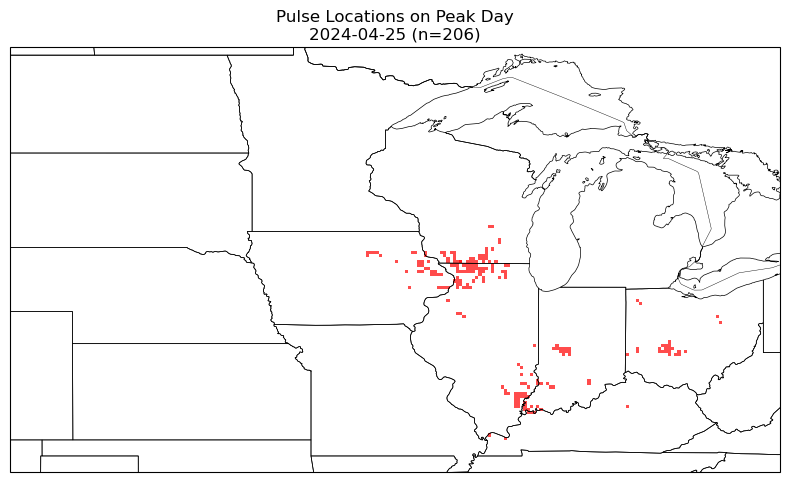

In [21]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
import numpy as np

# subset pulses on that day
pulse_map = df_plot[
    (df_plot["pulse_start"] == True) &
    (df_plot["date"] == peak_day)
].copy()

# get grid spacing
lat_vals = np.sort(df_plot["grid_lat"].unique())
lon_vals = np.sort(df_plot["grid_lon"].unique())

dlat = np.median(np.diff(lat_vals))
dlon = np.median(np.diff(lon_vals))

# plot
fig = plt.figure(figsize=(8,8))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([-104, -80, 36, 49])

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.3)

# draw pulse cells
for _, row in pulse_map.iterrows():
    rect = Rectangle(
        (row["grid_lon"] - dlon/2, row["grid_lat"] - dlat/2),
        dlon,
        dlat,
        facecolor="red",
        edgecolor=None,
        alpha=0.7,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)



plt.title(f"Pulse Locations on Peak Day\n{peak_day.date()} (n={peak_count})")

plt.tight_layout()
plt.show()

In [23]:
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])
df_plot["date"] = df_plot["datetime"].dt.floor("D")

# peak pulse day
pulse_daily = (
    df_plot[df_plot["pulse_start"] == True]
    .groupby("date")
    .size()
    .reset_index(name="n_pulses")
    .sort_values("n_pulses", ascending=False)
)

peak_day = pulse_daily.iloc[0]["date"]

# grid cells involved in that day
event_cells = (
    df_plot[
        (df_plot["pulse_start"] == True) &
        (df_plot["date"] == peak_day)
    ][["grid_lat", "grid_lon"]]
    .drop_duplicates()
)

In [24]:
# subset full time series for those cells
event_df = df_plot.merge(event_cells, on=["grid_lat", "grid_lon"])

# aggregate over those cells
event_ts = (
    event_df.groupby("datetime")
    .agg(
        precip=("h_precip_mm", "mean"),
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean")
    )
    .reset_index()
)

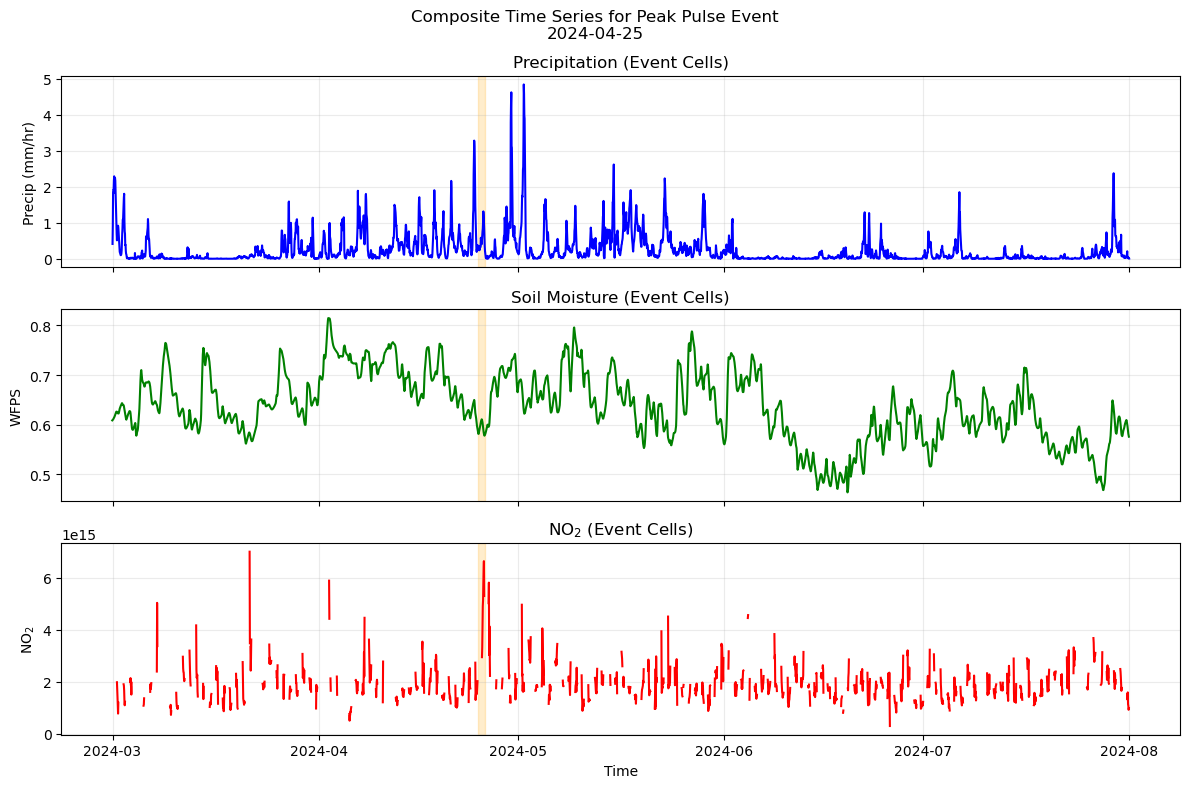

In [25]:

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# precip
axes[0].plot(event_ts["datetime"], event_ts["precip"], color="blue")
axes[0].set_ylabel("Precip (mm/hr)")
axes[0].set_title("Precipitation (Event Cells)")
axes[0].grid(alpha=0.25)

# WFPS
axes[1].plot(event_ts["datetime"], event_ts["WFPS"], color="green")
axes[1].set_ylabel("WFPS")
axes[1].set_title("Soil Moisture (Event Cells)")
axes[1].grid(alpha=0.25)

# NO2
axes[2].plot(event_ts["datetime"], event_ts["NO2"], color="red")
axes[2].set_ylabel("NO$_2$")
axes[2].set_title("NO$_2$ (Event Cells)")
axes[2].set_xlabel("Time")
axes[2].grid(alpha=0.25)

# highlight peak day
for ax in axes:
    ax.axvspan(peak_day, peak_day + pd.Timedelta(days=1),
               color="orange", alpha=0.2)

plt.suptitle(f"Composite Time Series for Peak Pulse Event\n{peak_day.date()}")
plt.tight_layout()
plt.show()

In [26]:
# define window
start = peak_day - pd.Timedelta(days=7)
end   = peak_day + pd.Timedelta(days=7)

event_ts_window = event_ts[
    (event_ts["datetime"] >= start) &
    (event_ts["datetime"] <= end)
].copy()

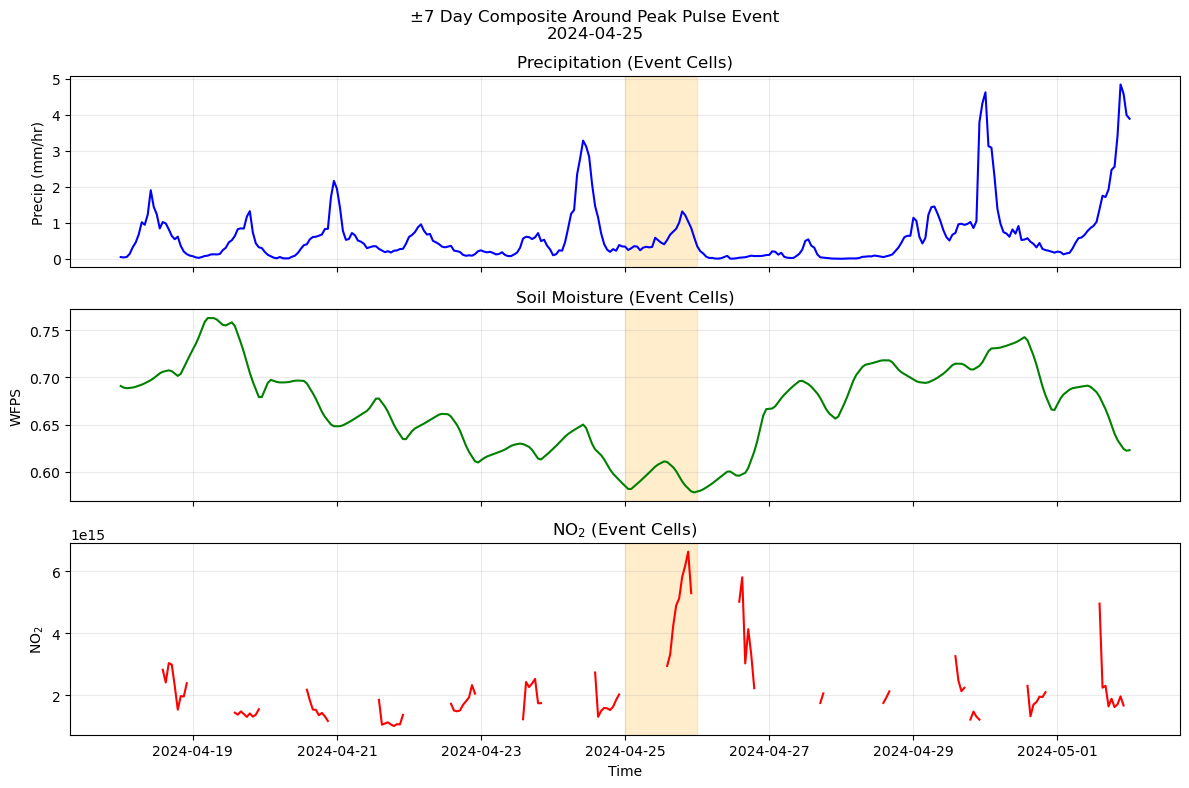

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# precip
axes[0].plot(event_ts_window["datetime"], event_ts_window["precip"], color="blue")
axes[0].set_ylabel("Precip (mm/hr)")
axes[0].set_title("Precipitation (Event Cells)")
axes[0].grid(alpha=0.25)

# WFPS
axes[1].plot(event_ts_window["datetime"], event_ts_window["WFPS"], color="green")
axes[1].set_ylabel("WFPS")
axes[1].set_title("Soil Moisture (Event Cells)")
axes[1].grid(alpha=0.25)

# NO2
axes[2].plot(event_ts_window["datetime"], event_ts_window["NO2"], color="red")
axes[2].set_ylabel("NO$_2$")
axes[2].set_title("NO$_2$ (Event Cells)")
axes[2].set_xlabel("Time")
axes[2].grid(alpha=0.25)

# highlight peak day
for ax in axes:
    ax.axvspan(peak_day, peak_day + pd.Timedelta(days=1),
               color="orange", alpha=0.2)

plt.suptitle(f"±7 Day Composite Around Peak Pulse Event\n{peak_day.date()}")
plt.tight_layout()
plt.show()

In [28]:
grouping_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_grouped_2hour_pulses.parquet'
group_df = pd.read_parquet(grouping_file, engine='pyarrow')

In [29]:
group_df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class,time_num,group_id
0,37.35,-100.85,0.000,2024-03-13 16:00:00,2.173031e+15,6.369229e+14,1.273846e+14,0.0,0.0,0.293103,...,0.000000,0.0,75.000000,0.000000,22.727273,Kansas,-0.000005,decreasing,0.0,0
1,39.35,-92.75,0.000,2024-03-16 15:00:00,4.694567e+15,8.246832e+14,1.649366e+14,0.0,0.0,0.175668,...,0.000000,0.0,77.272727,0.000000,20.454545,Missouri,0.000689,increasing,71.0,1
2,39.15,-92.95,0.000,2024-03-16 15:00:00,2.622688e+15,1.454574e+15,2.969137e+14,0.0,0.0,0.554612,...,5.303030,0.0,71.969697,2.272727,11.363636,Missouri,0.000744,increasing,71.0,3
3,39.15,-92.85,0.000,2024-03-16 15:00:00,2.632403e+15,1.870482e+15,3.740963e+14,0.0,0.0,0.710561,...,1.388889,0.0,88.888889,0.694444,4.166667,Missouri,0.000872,increasing,71.0,3
4,39.15,-93.15,0.000,2024-03-16 15:00:00,2.643212e+15,1.089365e+15,2.178731e+14,0.0,0.0,0.412137,...,0.000000,0.0,100.000000,0.000000,0.000000,Missouri,0.000546,increasing,71.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2004,40.85,-95.05,0.000,2024-07-19 15:00:00,3.003975e+15,5.779969e+14,1.155994e+14,0.0,0.0,0.192411,...,0.000000,0.0,9.917355,0.000000,90.082645,Iowa,-0.000296,decreasing,3071.0,2004
2005,40.95,-94.75,0.000,2024-07-19 16:00:00,2.530260e+15,9.967452e+14,2.417462e+14,0.0,0.0,0.393930,...,0.000000,0.0,14.583333,0.000000,84.722222,Iowa,-0.000236,decreasing,3072.0,2005
2006,37.55,-98.35,0.105,2024-07-19 18:00:00,2.812737e+15,7.392236e+14,1.478447e+14,0.0,0.0,0.262813,...,45.454545,0.0,11.570248,0.000000,0.000000,Kansas,0.000606,increasing,3074.0,2006
2007,37.75,-98.65,0.000,2024-07-19 18:00:00,2.959582e+15,9.768195e+14,1.953639e+14,0.0,0.0,0.330053,...,81.818182,0.0,0.000000,0.000000,0.000000,Kansas,-0.000047,decreasing,3074.0,2007


In [30]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = group_df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# -----------------------------
# 1. UNGROUPED (pixel pulses)
# -----------------------------
ungrouped_ts = (
    df_plot.groupby("datetime")
    .size()
    .reset_index(name="pixel_pulses")
)

# -----------------------------
# 2. GROUPED (events)
# -----------------------------
# get ONE time per event (start time)
event_times = (
    df_plot.groupby("group_id")["datetime"]
    .min()
    .reset_index()
)

grouped_ts = (
    event_times.groupby("datetime")
    .size()
    .reset_index(name="event_pulses")
)

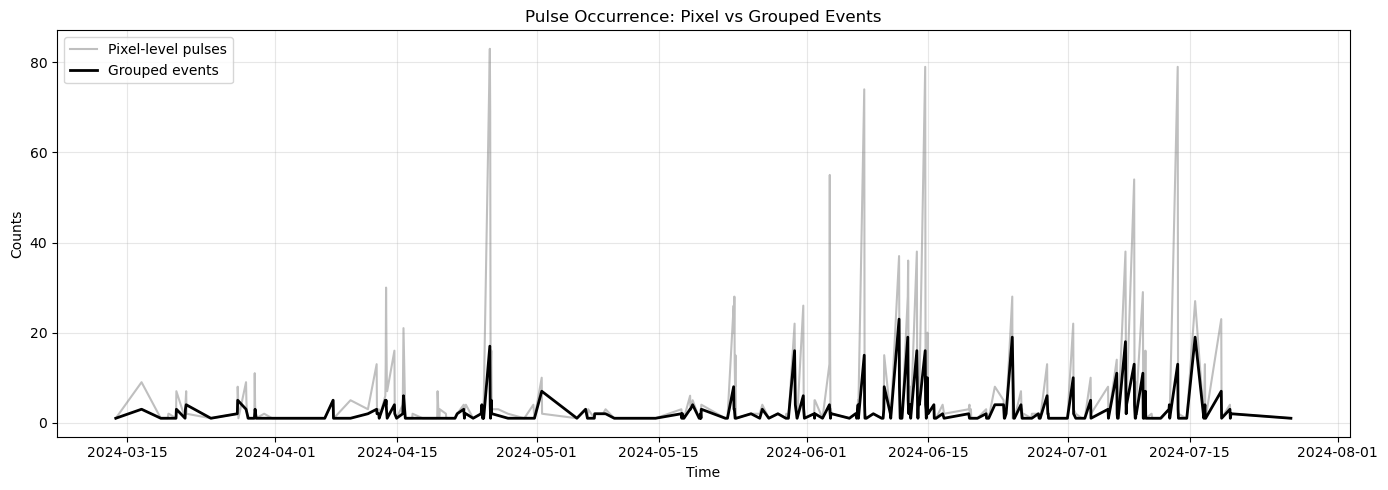

In [31]:
fig, ax = plt.subplots(figsize=(14,5))

# pixel-level pulses
ax.plot(
    ungrouped_ts["datetime"],
    ungrouped_ts["pixel_pulses"],
    color="gray",
    alpha=0.5,
    label="Pixel-level pulses"
)

# event-level pulses
ax.plot(
    grouped_ts["datetime"],
    grouped_ts["event_pulses"],
    color="black",
    linewidth=2,
    label="Grouped events"
)

ax.set_xlabel("Time")
ax.set_ylabel("Counts")
ax.set_title("Pulse Occurrence: Pixel vs Grouped Events")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

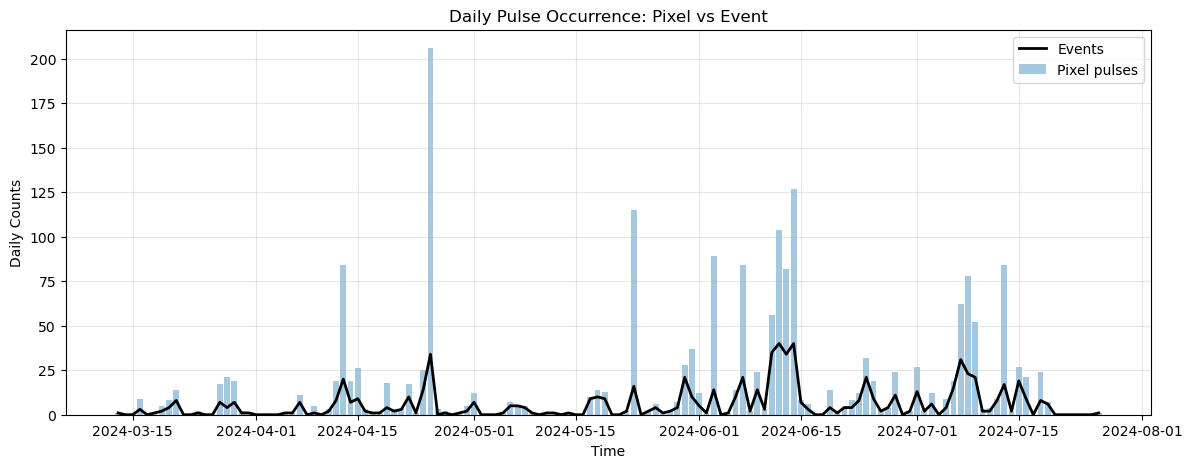

In [32]:
# daily aggregation
ungrouped_daily = (
    ungrouped_ts.set_index("datetime")
    .resample("1D")
    .sum()
    .reset_index()
)

grouped_daily = (
    grouped_ts.set_index("datetime")
    .resample("1D")
    .sum()
    .reset_index()
)

plt.figure(figsize=(14,5))

plt.bar(
    ungrouped_daily["datetime"],
    ungrouped_daily["pixel_pulses"],
    alpha=0.4,
    label="Pixel pulses"
)

plt.plot(
    grouped_daily["datetime"],
    grouped_daily["event_pulses"],
    color="black",
    linewidth=2,
    label="Events"
)

plt.xlabel("Time")
plt.ylabel("Daily Counts")
plt.title("Daily Pulse Occurrence: Pixel vs Event")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

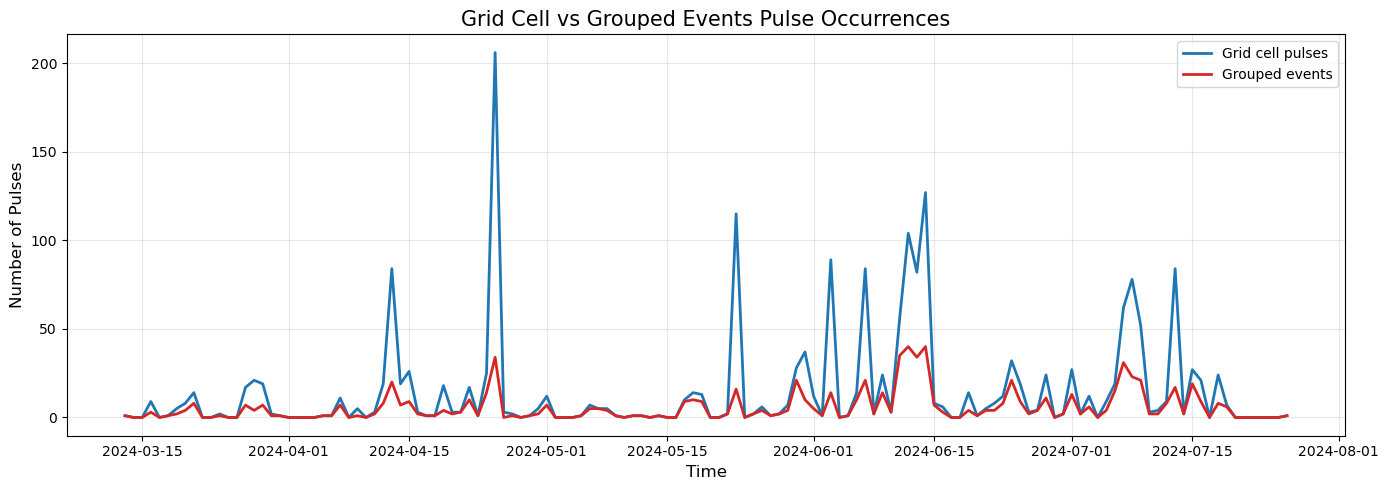

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = group_df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# -----------------------------
# UNGROUPED (pixel pulses)
# -----------------------------
ungrouped_ts = (
    df_plot.groupby("datetime")
    .size()
    .reset_index(name="pixel_pulses")
)

# -----------------------------
# GROUPED (event starts)
# -----------------------------
event_times = (
    df_plot.groupby("group_id")["datetime"]
    .min()
    .reset_index()
)

grouped_ts = (
    event_times.groupby("datetime")
    .size()
    .reset_index(name="event_pulses")
)

# -----------------------------
# DAILY aggregation
# -----------------------------
ungrouped_daily = (
    ungrouped_ts.set_index("datetime")
    .resample("1D")
    .sum()
)

grouped_daily = (
    grouped_ts.set_index("datetime")
    .resample("1D")
    .sum()
)

# align indices
combined = pd.concat([ungrouped_daily, grouped_daily], axis=1).fillna(0)

# -----------------------------
# PLOT (two colored lines)
# -----------------------------
plt.figure(figsize=(14,5))

plt.plot(
    combined.index,
    combined["pixel_pulses"],
    color="tab:blue",
    linewidth=2,
    label="Grid cell pulses"
)

plt.plot(
    combined.index,
    combined["event_pulses"],
    color="tab:red",
    linewidth=2,
    label="Grouped events"
)

plt.xlabel("Time", fontsize=12)
plt.ylabel("Number of Pulses", fontsize=12)
plt.title("Grid Cell vs Grouped Events Pulse Occurrences", fontsize=15)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

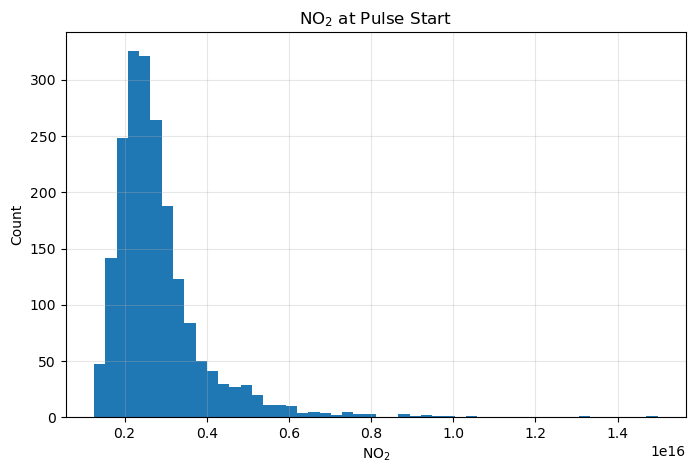

In [34]:
import matplotlib.pyplot as plt

pulse_df = df[df["pulse_start"] == True].copy()

plt.figure(figsize=(8,5))

plt.hist(
    pulse_df["no2_scaled_by_hour"].dropna(),
    bins=50
)

plt.xlabel("NO$_2$")
plt.ylabel("Count")
plt.title("NO$_2$ at Pulse Start")

plt.grid(alpha=0.3)
plt.show()

In [38]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_merged_all_datasets_allcols.parquet'
df_all = pd.read_parquet(file, engine='pyarrow')

In [39]:
file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df_all = pd.read_parquet(file, engine='pyarrow')

In [40]:
df_plot = df_all.copy()

# pulse starts
pulse_df = df_plot[df_plot["pulse_start"] == True].copy()

# background / non-pulse points
bg_df = df_plot[df_plot["pulse_start"] == False].copy()

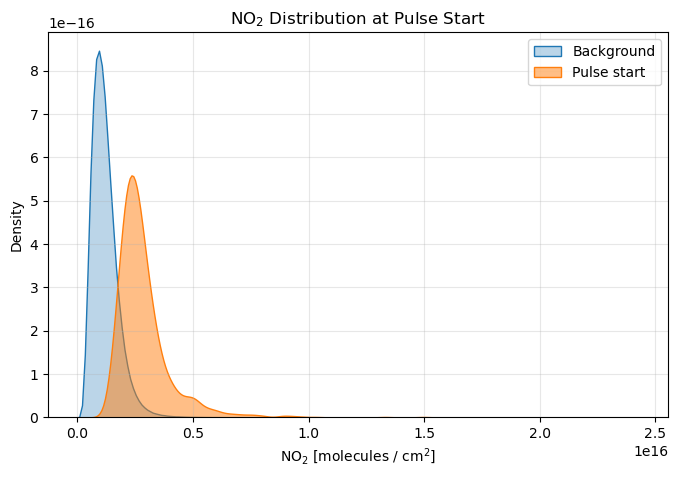

In [41]:
import seaborn as sns

plt.figure(figsize=(8,5))

sns.kdeplot(
    bg_df["no2_scaled_by_hour"],
    label="Background",
    fill=True,
    alpha=0.3
)

sns.kdeplot(
    pulse_df["no2_scaled_by_hour"],
    label="Pulse start",
    fill=True,
    alpha=0.5
)

plt.xlabel("NO$_2$ [molecules / cm$^2$]")
plt.ylabel("Density")
plt.title("NO$_2$ Distribution at Pulse Start")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

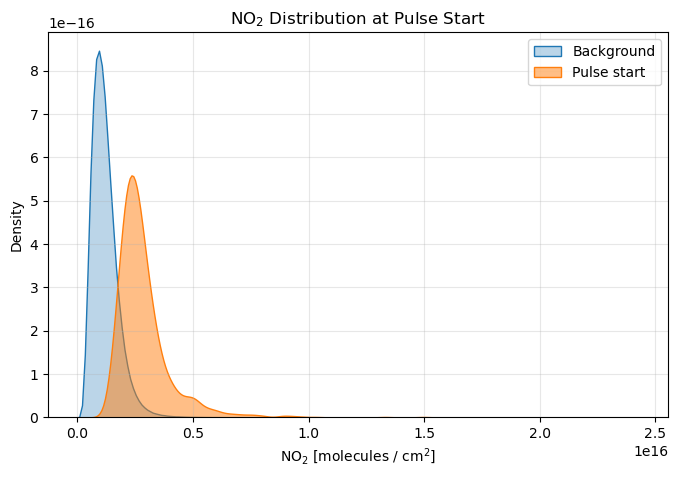

In [42]:
plt.figure(figsize=(8,5))

sns.kdeplot(
    bg_df["no2_scaled_by_hour"].dropna(),
    label="Background",
    fill=True,
    alpha=0.3,
    common_norm=True,   # <-- KEY
    bw_adjust=1
)

sns.kdeplot(
    pulse_df["no2_scaled_by_hour"].dropna(),
    label="Pulse start",
    fill=True,
    alpha=0.5,
    common_norm=True,   # <-- KEY
    bw_adjust=1
)

plt.xlabel("NO$_2$ [molecules / cm$^2$]")
plt.ylabel("Density")
plt.title("NO$_2$ Distribution at Pulse Start")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

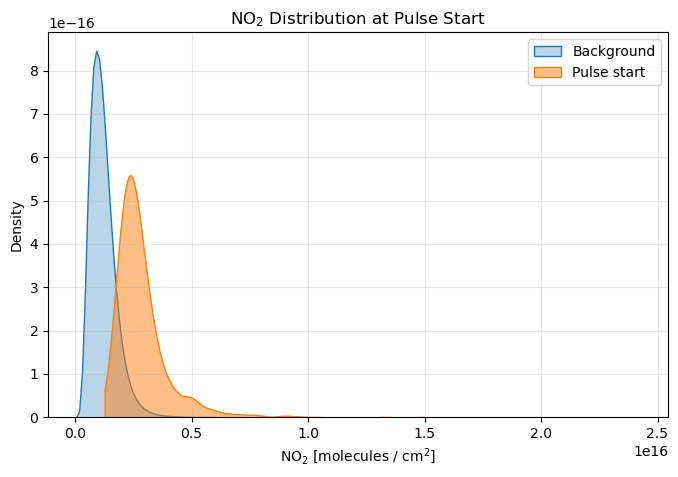

In [43]:
plt.figure(figsize=(8,5))

sns.kdeplot(
    bg_df["no2_scaled_by_hour"].dropna(),
    label="Background",
    fill=True,
    alpha=0.3,
    common_norm=True,
    bw_adjust=1,
    cut=0
)

sns.kdeplot(
    pulse_df["no2_scaled_by_hour"].dropna(),
    label="Pulse start",
    fill=True,
    alpha=0.5,
    common_norm=True,
    bw_adjust=1,
    cut=0
)

plt.xlabel("NO$_2$ [molecules / cm$^2$]")
plt.ylabel("Density")
plt.title("NO$_2$ Distribution at Pulse Start")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [44]:
df_all.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

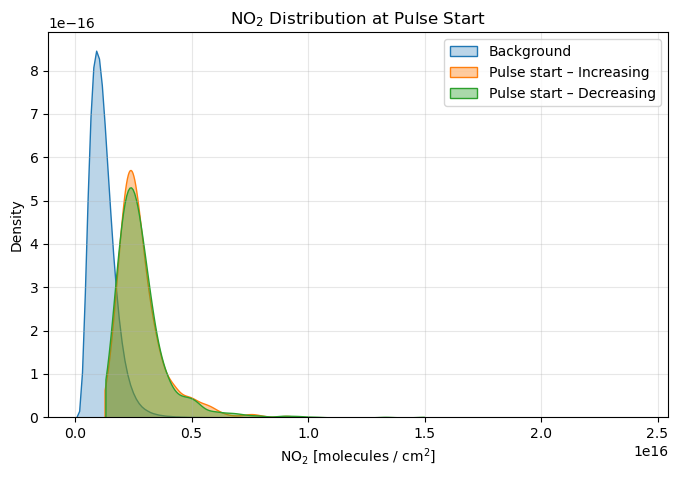

In [47]:
# Split pulse_df by sm_class
pulse_inc = pulse_df[pulse_df["sm_class"] == "increasing"]["no2_scaled_by_hour"].dropna()
pulse_dec = pulse_df[pulse_df["sm_class"] == "decreasing"]["no2_scaled_by_hour"].dropna()

plt.figure(figsize=(8, 5))

sns.kdeplot(
    bg_df["no2_scaled_by_hour"].dropna(),
    label="Background",
    fill=True,
    alpha=0.3,
    common_norm=True,
    bw_adjust=1,
    cut=0
)
sns.kdeplot(
    pulse_inc,
    label="Pulse start – Increasing",
    fill=True,
    alpha=0.4,
    common_norm=True,
    bw_adjust=1,
    cut=0
)
sns.kdeplot(
    pulse_dec,
    label="Pulse start – Decreasing",
    fill=True,
    alpha=0.4,
    common_norm=True,
    bw_adjust=1,
    cut=0
)

plt.xlabel("NO$_2$ [molecules / cm$^2$]")
plt.ylabel("Density")
plt.title("NO$_2$ Distribution at Pulse Start")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [48]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name'],
      dtype='object')